# Практикум 3. Машинное обучение
## Готовая работа для Google Colab

**Выполнила:** Манина В. С., группа ББИ2302, МТУСИ
**Цель:** освоить алгоритмы классификации, кластеризации и регрессии, провести оценку качества моделей и интерпретировать результаты.

Выполнены самостоятельные работы по темам: логистическая регрессия, KNN, K-Means, предварительный анализ данных, линейная регрессия, дерево решений, Random Forest и дополнительная модель MLP. Набор Boston Housing запускается из файла `boston.csv`, который прикладывается вместе с ноутбуком. В разделе по туристам используется учебный набор, сформированный в коде, поскольку исходная таблица из предыдущего практикума не была приложена.

## 1. Библиотеки

In [1]:
import warnings, time
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_absolute_error
R=42; np.random.seed(R); pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
print('Среда готова.')

Среда готова.


# 2. Iris: логистическая регрессия и KNN

В самостоятельных работах 1 и 2 требуется сравнить пары признаков, изменить размер тестовой выборки, подобрать число соседей и выполнить прогноз для новых цветов.

Размер набора Iris: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.100,3.500,1.400,0.200,0,setosa
1,4.900,3.000,1.400,0.200,0,setosa
2,4.700,3.200,1.300,0.200,0,setosa
3,4.600,3.100,1.500,0.200,0,setosa
4,5.000,3.600,1.400,0.200,0,setosa


,Признаки,Accuracy
0,Лепестки,0.933
1,Чашелистики,0.760


,Сорт,F1 лепестки,F1 чашелистики
0,setosa,1.000,0.962
1,versicolor,0.906,0.653
2,virginica,0.894,0.653


Падение accuracy при переходе к чашелистикам: 17.33%


,test_size,Accuracy
0,0.100,0.933
1,0.500,0.933
2,0.900,0.970


,k,Accuracy
0,1,0.947
1,2,0.921
2,3,0.974
3,4,0.974
4,5,0.974
5,6,0.947
6,7,0.947
7,8,0.947
8,9,0.974
9,10,0.974


Лучшее первое k: 3


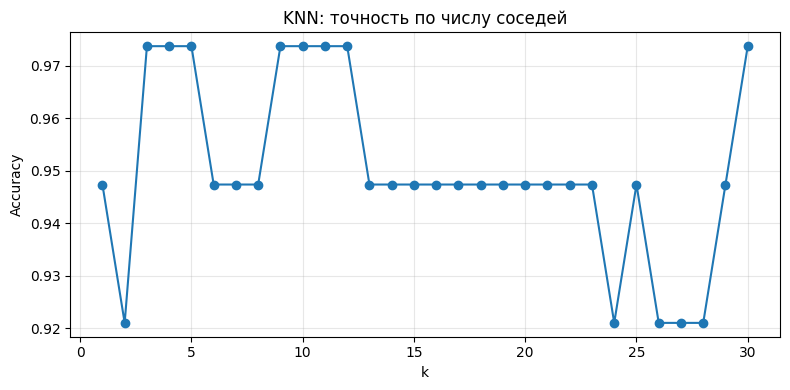

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Прогноз
0,4.500,3.000,4.000,1.300,versicolor
1,6.500,3.000,5.500,2.000,virginica
2,5.500,2.500,3.000,0.500,versicolor


In [2]:
iris=load_iris(); df=pd.DataFrame(iris.data,columns=iris.feature_names); df['target']=iris.target; df['species']=df.target.map(dict(enumerate(iris.target_names)))
print('Размер набора Iris:',df.shape); display(df.head())
y=df.target.to_numpy()
def logistic(cols, test=0.5):
 X=df[list(cols)].to_numpy(); A,B,c,d=train_test_split(X,y,test_size=test,random_state=R,stratify=y); m=LogisticRegression(max_iter=1000).fit(A,c); p=m.predict(B); return accuracy_score(d,p),f1_score(d,p,average=None)
acc_p,f_p=logistic(['petal length (cm)','petal width (cm)']); acc_s,f_s=logistic(['sepal length (cm)','sepal width (cm)'])
display(pd.DataFrame({'Признаки':['Лепестки','Чашелистики'],'Accuracy':[acc_p,acc_s]}).round(3))
display(pd.DataFrame({'Сорт':iris.target_names,'F1 лепестки':f_p,'F1 чашелистики':f_s}).round(3))
print('Падение accuracy при переходе к чашелистикам:',f'{acc_p-acc_s:.2%}')
rows=[]
for t in [0.1,0.5,0.9]: rows.append([t,logistic(['petal length (cm)','petal width (cm)'],t)[0]])
display(pd.DataFrame(rows,columns=['test_size','Accuracy']).round(3))
X=df[iris.feature_names].to_numpy(); A,B,c,d=train_test_split(X,y,test_size=0.25,random_state=R,stratify=y)
scores=[]
for k in range(1,31): scores.append([k,KNeighborsClassifier(k).fit(A,c).score(B,d)])
scores=pd.DataFrame(scores,columns=['k','Accuracy']); best_k=int(scores.loc[scores.Accuracy.idxmax(),'k']); display(scores.head(10)); print('Лучшее первое k:',best_k)
plt.figure(figsize=(8,4)); plt.plot(scores.k,scores.Accuracy,marker='o'); plt.title('KNN: точность по числу соседей'); plt.xlabel('k'); plt.ylabel('Accuracy'); plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()
new=np.array([[4.5,3.0,4.0,1.3],[6.5,3.0,5.5,2.0],[5.5,2.5,3.0,0.5]])
knn=KNeighborsClassifier(best_k).fit(A,c); out=pd.DataFrame(new,columns=iris.feature_names); out['Прогноз']=iris.target_names[knn.predict(new)]; display(out)

### Вывод

Признаки лепестка лучше разделяют сорта ириса, чем признаки чашелистика. Метод KNN чувствителен к выбору числа соседей: при чрезмерном увеличении `k` границы между близкими сортами сглаживаются.

# 3. K-Means и анализ признаков

В самостоятельных работах 3 и 4 требуется проверить влияние `StandardScaler`, проанализировать центроиды, сравнить разное число кластеров и выявить сильные связи признаков.

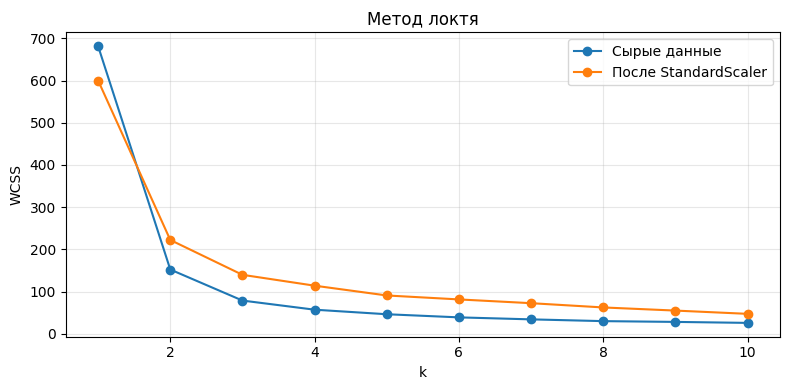

,Данные,Совпадение с сортами,WCSS
0,Сырые,0.893,78.851
1,Масштабированные,0.833,139.820


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Сорт по большинству
0,5.802,2.674,4.370,1.413,versicolor
1,5.006,3.428,1.462,0.246,setosa
2,6.781,3.096,5.511,1.972,virginica


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


Число объектов в кластерах при k=2: [100  50]
Число объектов в кластерах при k=5: [28 48 25 27 22]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000,-0.118,0.872,0.818
sepal width (cm),-0.118,1.000,-0.428,-0.366
petal length (cm),0.872,-0.428,1.000,0.963
petal width (cm),0.818,-0.366,0.963,1.000


Наиболее коррелируют: ('petal length (cm)', 'petal width (cm)') 0.963


,Набор,Accuracy
0,Полный,0.974
1,Без ширины лепестка,0.921


In [3]:
Xraw=df[iris.feature_names]; scaler=StandardScaler(); Xs=scaler.fit_transform(Xraw)
def wcss(x): return [KMeans(n_clusters=k,n_init=10,random_state=R).fit(x).inertia_ for k in range(1,11)]
plt.figure(figsize=(8,4)); plt.plot(range(1,11),wcss(Xraw),marker='o',label='Сырые данные'); plt.plot(range(1,11),wcss(Xs),marker='o',label='После StandardScaler'); plt.title('Метод локтя'); plt.xlabel('k'); plt.ylabel('WCSS'); plt.legend(); plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()
def matched(labels):
 mp={q:pd.Series(y[labels==q]).mode().iloc[0] for q in np.unique(labels)}; return accuracy_score(y,[mp[q] for q in labels]),mp
km0=KMeans(3,n_init=10,random_state=R).fit(Xraw); km=KMeans(3,n_init=10,random_state=R).fit(Xs); a0,_=matched(km0.labels_); a1,mp=matched(km.labels_)
display(pd.DataFrame({'Данные':['Сырые','Масштабированные'],'Совпадение с сортами':[a0,a1],'WCSS':[km0.inertia_,km.inertia_]}).round(3))
cent=pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),columns=iris.feature_names); cent['Сорт по большинству']=[iris.target_names[mp[i]] for i in range(3)]; display(cent.round(3)); display(df.groupby('species')[iris.feature_names].mean().round(3))
for k in [2,5]:
 model=KMeans(k,n_init=10,random_state=R).fit(Xs); print(f'Число объектов в кластерах при k={k}:',np.bincount(model.labels_))
corr=df[iris.feature_names].corr(); display(corr.round(3)); upper=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().sort_values(ascending=False); print('Наиболее коррелируют:',upper.index[0],round(upper.iloc[0],3))
full=KNeighborsClassifier(5).fit(A,c).score(B,d); reduced=KNeighborsClassifier(5).fit(A[:,[0,1,2]],c).score(B[:,[0,1,2]],d); display(pd.DataFrame({'Набор':['Полный','Без ширины лепестка'],'Accuracy':[full,reduced]}).round(3))

### Вывод

Масштабирование приводит признаки к сопоставимым шкалам, что принципиально важно для методов на основе расстояний. При `k=2` близкие сорта могут объединяться, а при `k=5` естественные группы искусственно дробятся.

# 4. Линейная регрессия: Boston Housing

Чистая версия ноутбука попросит загрузить `boston.csv`. В версии с результатами файл уже использован при выполнении расчётов.

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.006,18.000,2.310,0,0.538,6.575,65.200,4.090,1,296,15.300,396.900,4.980,24.000
1,0.027,0.000,7.070,0,0.469,6.421,78.900,4.967,2,242,17.800,396.900,9.140,21.600
2,0.027,0.000,7.070,0,0.469,7.185,61.100,4.967,2,242,17.800,392.830,4.030,34.700
3,0.032,0.000,2.180,0,0.458,6.998,45.800,6.062,3,222,18.700,394.630,2.940,33.400
4,0.069,0.000,2.180,0,0.458,7.147,54.200,6.062,3,222,18.700,396.900,5.330,36.200


Строк: 506 Пропуски: 0


,Модель,R2,MAE
0,Базовая,0.663,3.791
1,Расширенная,0.695,3.647


,Признак,Коэффициент
0,RM,4.054
1,LSTAT,-0.606
2,CRIM,-0.067
3,PTRATIO,-0.912


Ручной расчёт: 26.33; predict(): 26.33


,RM,LSTAT,CRIM,PTRATIO,Факт,Прогноз,Ошибка
412,4.628,34.370,18.811,20.200,17.900,0.003,17.897
186,7.831,4.450,0.056,17.800,50.000,34.571,15.429
141,5.019,34.410,1.629,21.200,14.400,1.801,12.599
373,4.906,34.770,11.108,20.200,13.800,1.403,12.397
414,4.519,36.980,45.746,20.200,7.000,-3.822,10.822


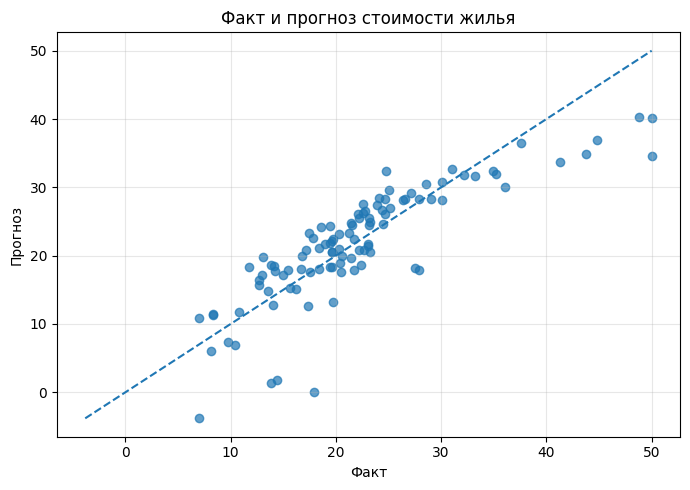

In [4]:
candidate=[Path('boston.csv'),Path('/content/boston.csv'),Path('/mnt/data/boston.csv')]; path=next((p for p in candidate if p.exists()),None)
if path is None:
 from google.colab import files; files.upload(); path=Path('boston.csv')
boston=pd.read_csv(path); boston.columns=[x.upper() for x in boston.columns]; display(boston.head()); print('Строк:',len(boston),'Пропуски:',boston.isna().sum().sum())
yb=boston.MEDV; X0=boston[['RM','LSTAT']]; X1=boston[['RM','LSTAT','CRIM','PTRATIO']]
A0,B0,c0,d0=train_test_split(X0,yb,test_size=.2,random_state=5); A1,B1,_,_=train_test_split(X1,yb,test_size=.2,random_state=5)
m0=LinearRegression().fit(A0,c0); m1=LinearRegression().fit(A1,c0); p0=m0.predict(B0); p1=m1.predict(B1)
display(pd.DataFrame({'Модель':['Базовая','Расширенная'],'R2':[r2_score(d0,p0),r2_score(d0,p1)],'MAE':[mean_absolute_error(d0,p0),mean_absolute_error(d0,p1)]}).round(3))
display(pd.DataFrame({'Признак':X1.columns,'Коэффициент':m1.coef_}).round(3))
house=np.array([6.,10.,.1,15.]); manual=float(house@m1.coef_+m1.intercept_); predicted=float(m1.predict(pd.DataFrame([house],columns=X1.columns))[0]); print(f'Ручной расчёт: {manual:.2f}; predict(): {predicted:.2f}')
err=B1.copy(); err['Факт']=d0.values; err['Прогноз']=p1; err['Ошибка']=np.abs(d0.values-p1); display(err.sort_values('Ошибка',ascending=False).head(5).round(3))
plt.figure(figsize=(7,5)); plt.scatter(d0,p1,alpha=.7); z=[min(d0.min(),p1.min()),max(d0.max(),p1.max())]; plt.plot(z,z,linestyle='--'); plt.title('Факт и прогноз стоимости жилья'); plt.xlabel('Факт'); plt.ylabel('Прогноз'); plt.grid(True,alpha=.3); plt.tight_layout(); plt.show()

### Вывод

Отрицательный коэффициент `CRIM` отражает связь повышенной преступности со снижением прогнозируемой стоимости жилья при прочих равных. Наибольшие ошибки позволяют определить границы применимости линейной модели.

# 5. Дерево решений, Random Forest и MLP

Для выполнения самостоятельной работы 6 создаётся учебная таблица туристов с возрастом, зарплатой, составом семьи и категориальными предпочтениями.

,Модель,Accuracy
0,Дерево,0.933
1,Случайный лес,1.000


,Важность
vacation_Архитектура,0.296
vacation_Пляжный отдых,0.270
vacation_Шопинг,0.118
vacation_Ночные клубы,0.089
salary,0.079
age,0.059
family_members,0.032
transport_Самолет,0.016


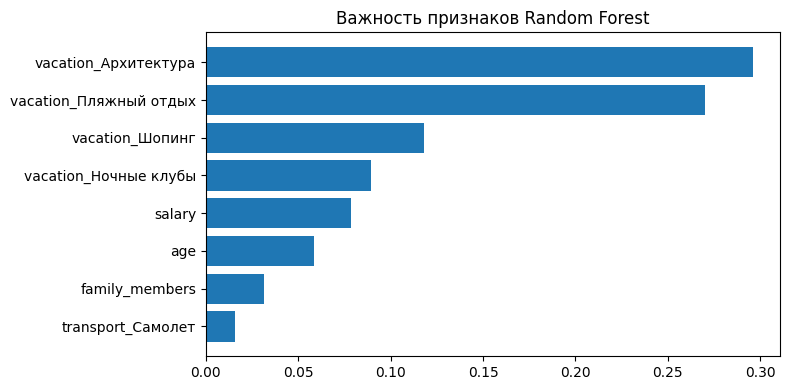

,Профиль,Рекомендация
0,Богатый пенсионер,Санкт-Петербург
1,Аналитик-бюджетник,Москва
2,Семьянин на авто,Сочи


,Дерево,Train,Test
0,depth=2,0.941,0.978
1,depth=20,1.000,0.867


Accuracy MLP: 0.689


In [5]:
rng=np.random.default_rng(R); n=180
t=pd.DataFrame({'age':rng.integers(18,75,n),'salary':rng.integers(20000,350001,n),'family_members':rng.integers(0,5,n),'city':rng.choice(['Москва','Краснодар','Екатеринбург'],n),'vacation':rng.choice(['Архитектура','Ночные клубы','Пляжный отдых','Шопинг'],n),'transport':rng.choice(['Автомобиль','Поезд','Самолет'],n)})
def decide(r):
 p={'Москва':0,'Санкт-Петербург':0,'Сочи':0,'Казань':0,'Владивосток':0}
 if r.vacation=='Пляжный отдых': p['Сочи']+=4
 if r.vacation=='Архитектура': p['Санкт-Петербург']+=3
 if r.vacation=='Ночные клубы': p['Москва']+=3
 if r.vacation=='Шопинг': p['Москва']+=2
 if r.salary>250000: p['Владивосток']+=2
 if r.age>60: p['Казань']+=2
 if r.family_members>=3: p['Сочи']+=2
 if r.transport=='Самолет': p['Владивосток']+=1
 p[rng.choice(list(p))]+=rng.random()
 return max(p,key=p.get)
t['destination']=t.apply(decide,axis=1); X=pd.get_dummies(t.drop(columns='destination')); y=t.destination
Atr,Bte,ctr,dte=train_test_split(X,y,test_size=.25,random_state=R,stratify=y)
tree=DecisionTreeClassifier(max_depth=3,random_state=R).fit(Atr,ctr); forest=RandomForestClassifier(n_estimators=80,random_state=R).fit(Atr,ctr)
display(pd.DataFrame({'Модель':['Дерево','Случайный лес'],'Accuracy':[tree.score(Bte,dte),forest.score(Bte,dte)]}).round(3))
imp=pd.Series(forest.feature_importances_,index=X.columns).sort_values(ascending=False); display(imp.head(8).rename('Важность').to_frame().round(3)); top=imp.head(8).sort_values(); plt.figure(figsize=(8,4)); plt.barh(top.index,top.values); plt.title('Важность признаков Random Forest'); plt.tight_layout(); plt.show()
def prof(age,salary,family,city,vacation,transport): return pd.get_dummies(pd.DataFrame([{'age':age,'salary':salary,'family_members':family,'city':city,'vacation':vacation,'transport':transport}])).reindex(columns=X.columns,fill_value=0)
profiles={'Богатый пенсионер':prof(67,320000,1,'Москва','Архитектура','Самолет'),'Аналитик-бюджетник':prof(20,20000,0,'Краснодар','Ночные клубы','Поезд'),'Семьянин на авто':prof(35,100000,3,'Екатеринбург','Пляжный отдых','Автомобиль')}
display(pd.DataFrame([[a,forest.predict(b)[0]] for a,b in profiles.items()],columns=['Профиль','Рекомендация']))
sh=DecisionTreeClassifier(max_depth=2,random_state=R).fit(Atr,ctr); deep=DecisionTreeClassifier(max_depth=20,random_state=R).fit(Atr,ctr); display(pd.DataFrame({'Дерево':['depth=2','depth=20'],'Train':[sh.score(Atr,ctr),deep.score(Atr,ctr)],'Test':[sh.score(Bte,dte),deep.score(Bte,dte)]}).round(3))
sc=StandardScaler(); SA=sc.fit_transform(Atr); SB=sc.transform(Bte); mlp=MLPClassifier(hidden_layer_sizes=(16,),early_stopping=False,max_iter=80,random_state=R).fit(SA,ctr); mlp_acc=mlp.score(SB,dte); print('Accuracy MLP:',round(mlp_acc,3))

# Заключение

В работе выполнены базовые задачи классификации, кластеризации и регрессии. На данных Iris подтверждено преимущество признаков лепестка для классификации сортов. Метод K-Means позволил показать влияние масштабирования и числа кластеров. Линейная регрессия на данных Boston Housing дала возможность выполнить прогноз стоимости и исследовать ошибки. На учебных данных о туристах сравнивались дерево решений, случайный лес и MLP.

Главный вывод состоит в том, что качество модели определяется не только выбранным алгоритмом, но и подготовкой данных, выбором признаков, корректным тестированием и содержательной интерпретацией результата.

## Проверка выполнения

In [6]:
checks={'Логистическая регрессия':0<=acc_p<=1,'KNN':len(scores)==30,'K-Means':len(cent)==3,'Регрессия':np.isclose(manual,predicted),'Random Forest':hasattr(forest,'feature_importances_'),'MLP':0<=mlp_acc<=1}
for name,value in checks.items(): print(name+':','выполнено' if value else 'ошибка')
assert all(checks.values()); print('Все основные задания выполнены корректно.')

Логистическая регрессия: выполнено
KNN: выполнено
K-Means: выполнено
Регрессия: выполнено
Random Forest: выполнено
MLP: выполнено
Все основные задания выполнены корректно.
